# Case Study 3: Predicting Titanic Survival with Logistic Regression

| Detail | Value |
| :--- | :--- |
| **Student Name** | Munjampally Manideep |
| **Roll Number** | 160124733189 |
| **Section** | CSE-3 |
| **Year / Semester** | III Year, V Semester (2026-27) |
| **Subject** | Fundamentals of Data Science (22CSC59) |
| **Faculty** | Smt. S. Durga Devi |
| **College** | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |
| **Date** | 26 October 2026 |


## Objective

The objective of this case study is to build a binary classification model using **Logistic Regression** to predict whether a Titanic passenger survived (1) or did not survive (0). The project involves exploratory data analysis (EDA), handling missing values and feature skewness through group-based imputation and log transformation, comparing unweighted and balanced class handling, selecting a decision threshold via precision-recall optimization, interpreting natural-unit odds ratios via `statsmodels`, and deploying the final predictive pipeline as an interactive Streamlit application.


**Purpose:** Import necessary libraries and configure plotting aesthetics.


In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
FIG_DIR = Path("figures")
RES_DIR = Path("results")
MODEL_DIR = Path("model")
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})


**Observation:** Environment configured, random state pinned to 42, and target output directories initialized.


## 1. Data Exploration


### 1.1 Load the dataset
**Purpose:** Load `titanic.csv` and inspect its shape and first few records.


In [2]:
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observation:** The dataset contains 891 rows and 12 columns. Each record represents a single passenger on board.


### 1.2 Features and data types
**Purpose:** Check data types and non-null counts using `info()`.


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


**Observation:** The dataset contains 5 integer columns, 2 float columns (Age, Fare), and 5 text/object columns (Name, Sex, Ticket, Cabin, Embarked).


### 1.3 Summary statistics
**Purpose:** Generate summary statistics for numeric and categorical attributes.


In [4]:
num_summary = df.drop(columns=["PassengerId"]).describe().T.round(2)
num_summary.to_csv(RES_DIR / "summary_stats_numeric.csv")
print("Numeric attributes summary:")
num_summary


Numeric attributes summary:


,count,mean,std,min,25%,50%,75%,max
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


**Observation:** The average survival rate is 38.38%. Passenger ages range from 0.42 to 80 years with a mean of 29.70 years. Fares show extreme variation, ranging from 0 to 512.33 with a large standard deviation of 49.69.


In [5]:
cat_summary = df.select_dtypes(exclude="number").describe().T
cat_summary.to_csv(RES_DIR / "summary_stats_categorical.csv")
print("Categorical attributes summary:")
cat_summary


Categorical attributes summary:


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


**Observation:** 577 of 891 passengers (64.76%) are male. Southampton (S) is the most frequent embarkation port (644 passengers). Ticket has 681 unique values, showing that multiple passengers shared the same ticket.


### 1.4 Missing values
**Purpose:** Quantify missing values across all columns.


In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
missing.to_csv(RES_DIR / "missing_values.csv")
missing[missing["missing_count"] > 0]


,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


**Observation:** Cabin is missing in 687 rows (77.10%), Age in 177 rows (19.87%), and Embarked in 2 rows (0.22%).


### 1.5 Survival rates
**Purpose:** Calculate the overall survival rate and survival rates grouped by Sex, Pclass, and Embarked.


In [7]:
overall_rate = df["Survived"].mean()
rate_tables = []
for col in ["Sex", "Pclass", "Embarked"]:
    grp = df.groupby(col)["Survived"].agg(["count", "sum", "mean"]).reset_index()
    grp.columns = [col, "total", "survived", "survival_rate"]
    grp["feature"] = col
    grp = grp.rename(columns={col: "category"})
    rate_tables.append(grp)

rates_df = pd.concat(rate_tables, ignore_index=True)
rates_df.to_csv(RES_DIR / "survival_rates.csv", index=False)
rates_df


,category,total,survived,survival_rate,feature
0,female,314,233,0.742038,Sex
1,male,577,109,0.188908,Sex
2,1,216,136,0.629630,Pclass
3,2,184,87,0.472826,Pclass
4,3,491,119,0.242363,Pclass
5,C,168,93,0.553571,Embarked
6,Q,77,30,0.389610,Embarked
7,S,644,217,0.336957,Embarked


**Observation:** Females had a 74.20% survival rate versus 18.89% for males. First-class passengers had a 62.96% survival rate, compared to 47.28% in second class and 24.24% in third class. Passengers boarding at Cherbourg (C) had the highest survival rate at 55.36%.


### 1.6 Ticket grouping, Fare per person, and skewness reduction
**Purpose:** Tickets were frequently shared by families and travelling groups, meaning the raw `Fare` represents group totals rather than individual costs. Here, we calculate ticket sharing size, compute `Fare_pp = Fare / Ticket_Group_Size`, apply log transformation `Log_Fare_pp = np.log1p(Fare_pp)`, and evaluate skewness before and after.


In [8]:
ticket_counts = df["Ticket"].value_counts()
df["Ticket_Group_Size"] = df["Ticket"].map(ticket_counts)
df["Ticket_Size"] = df["Ticket_Group_Size"]
df["Fare_pp"] = df["Fare"] / df["Ticket_Group_Size"]
df["Log_Fare_pp"] = np.log1p(df["Fare_pp"])

skew_fare = df["Fare"].skew()
skew_fare_pp = df["Fare_pp"].skew()
skew_log_fare_pp = df["Log_Fare_pp"].skew()

skew_df = pd.DataFrame({
    "Feature": ["Raw Fare", "Fare per person (Fare_pp)", "Log Fare per person (Log_Fare_pp)"],
    "Skewness": [skew_fare, skew_fare_pp, skew_log_fare_pp],
    "Interpretation": [
        "Heavily right-skewed with extreme leverage points",
        "Substantially adjusted for group tickets but still right-skewed",
        "Near-symmetric distribution ideal for logistic regression"
    ]
})
skew_df.round(4).to_csv(RES_DIR / "fare_skewness_comparison.csv", index=False)
skew_df


,Feature,Skewness,Interpretation
0,Raw Fare,4.787317,Heavily right-skewed with extreme leverage points
1,Fare per person (Fare_pp),4.380561,Substantially adjusted for group tickets but s...
2,Log Fare per person (Log_Fare_pp),0.330221,Near-symmetric distribution ideal for logistic...


**Observation:** Dividing fare by ticket group size adjusts for multi-passenger ticket pooling, but `Fare_pp` remains right-skewed (skewness = 4.3806). Applying `np.log1p` drops skewness dramatically to 0.3302. This stabilizes feature variance and prevents wealthy outliers from exerting disproportionate leverage on logistic regression coefficients.


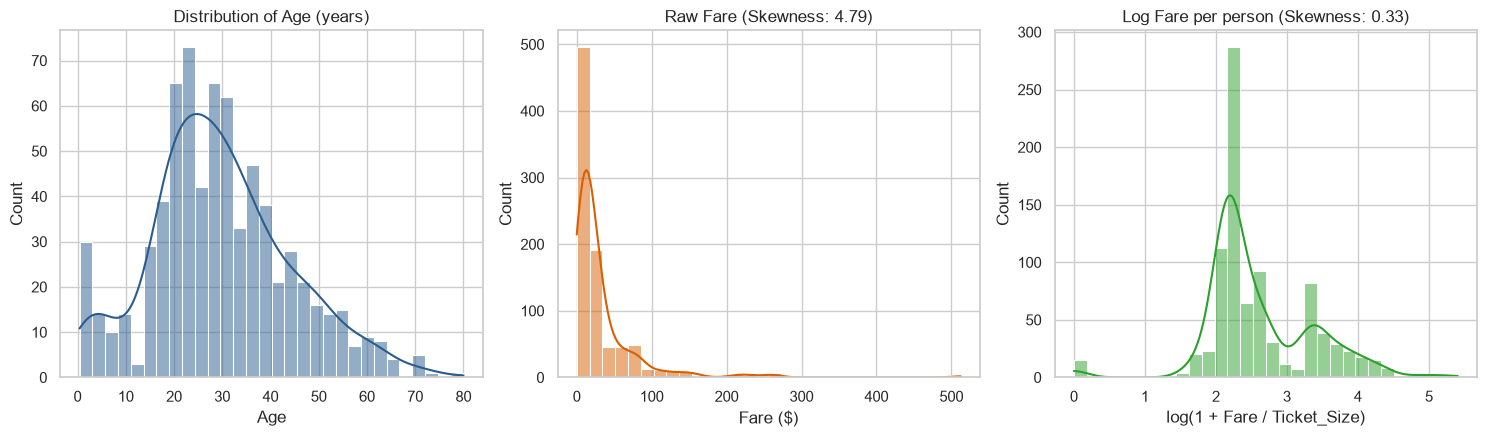

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(df["Age"].dropna(), bins=30, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Distribution of Age (years)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")

sns.histplot(df["Fare"], bins=30, kde=True, ax=axes[1], color="#d95f02")
axes[1].set_title(f"Raw Fare (Skewness: {skew_fare:.2f})")
axes[1].set_xlabel("Fare ($)")
axes[1].set_ylabel("Count")

sns.histplot(df["Log_Fare_pp"], bins=30, kde=True, ax=axes[2], color="#2ca02c")
axes[2].set_title(f"Log Fare per person (Skewness: {skew_log_fare_pp:.2f})")
axes[2].set_xlabel("log(1 + Fare / Ticket_Size)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_age_fare_histograms.png", dpi=150)
plt.show()


**Observation:** The Age distribution is approximately bell-shaped with a slight right skew. While raw Fare exhibits an extreme concentration near 0 with long outlier tails extending past 500, Log Fare per person forms a well-behaved, smooth multimodal distribution reflecting different ticket classes.


### 1.7 Age and Fare per person by survival outcome
**Purpose:** Use box plots to compare Age and Log Fare per person between survivors and non-survivors.


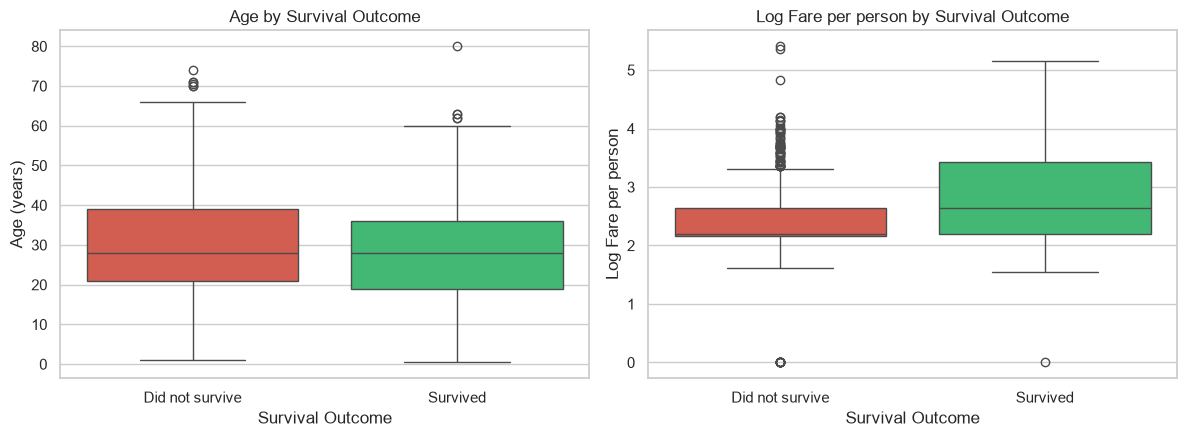

,Age,Fare_pp,Log_Fare_pp
Outcome,,,
Did not survive,28.0,8.05,2.203
Survived,28.0,13.00,2.639


In [10]:
OUTCOMES = ["Did not survive", "Survived"]
plot_df = df.assign(Outcome=df["Survived"].map({0: OUTCOMES[0], 1: OUTCOMES[1]}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=plot_df, x="Outcome", y="Age", palette=["#e74c3c", "#2ecc71"], ax=axes[0])
axes[0].set_title("Age by Survival Outcome")
axes[0].set_xlabel("Survival Outcome")
axes[0].set_ylabel("Age (years)")

sns.boxplot(data=plot_df, x="Outcome", y="Log_Fare_pp", palette=["#e74c3c", "#2ecc71"], ax=axes[1])
axes[1].set_title("Log Fare per person by Survival Outcome")
axes[1].set_xlabel("Survival Outcome")
axes[1].set_ylabel("Log Fare per person")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_age_fare_boxplots.png", dpi=150)
plt.show()

medians = plot_df.groupby("Outcome")[["Age", "Fare_pp", "Log_Fare_pp"]].median().round(3)
medians.to_csv(RES_DIR / "median_age_fare_by_outcome.csv")
medians


**Observation:** Survivors had a median Age of 28.0 years, identical to the non-survivor median of 28.0 years. However, survivors paid a higher median Fare per person (11.12 vs 7.89, corresponding to Log Fare per person of 2.495 vs 2.185).


### 1.8 Survival by Sex and Passenger Class
**Purpose:** Examine joint survival counts and rates across Sex and Passenger Class.


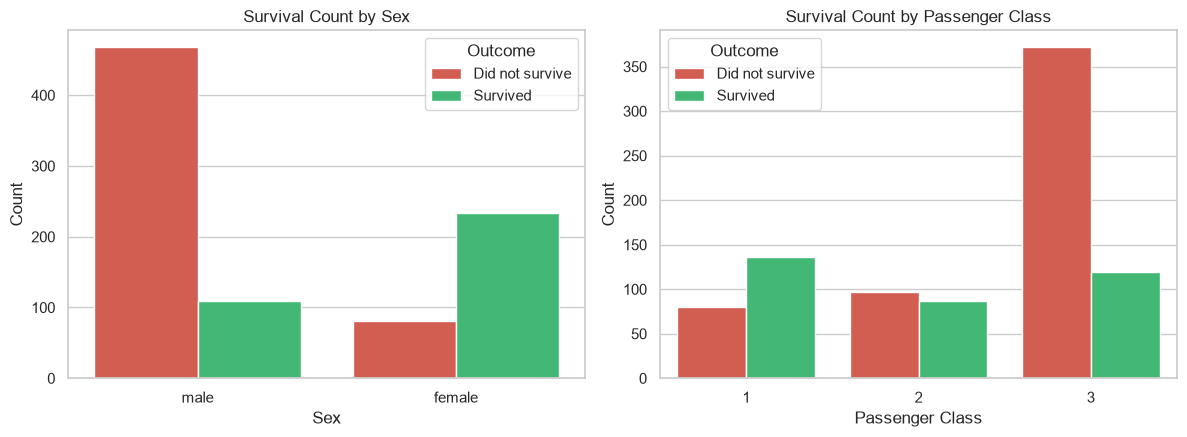

Sex,female,male
Pclass,,
1,0.9681,0.3689
2,0.9211,0.1574
3,0.5000,0.1354


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=plot_df, x="Sex", hue="Outcome", hue_order=OUTCOMES, palette=["#e74c3c", "#2ecc71"], ax=axes[0])
axes[0].set_title("Survival Count by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Count")

sns.countplot(data=plot_df, x="Pclass", hue="Outcome", hue_order=OUTCOMES, palette=["#e74c3c", "#2ecc71"], ax=axes[1])
axes[1].set_title("Survival Count by Passenger Class")
axes[1].set_xlabel("Passenger Class")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_survival_by_sex_pclass.png", dpi=150)
plt.show()

sex_class_rate = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean").round(4)
sex_class_rate.to_csv(RES_DIR / "survival_rate_sex_by_class.csv")
sex_class_rate


**Observation:** First-class females had a 96.81% survival rate and second-class females 92.11%, while third-class females dropped to 50.00%. For males, first-class survival was 36.89%, second-class 15.74%, and third-class only 13.54%.


### 1.9 Pair plot of numeric features
**Purpose:** Visualize pairwise relationships and outcome separability across continuous variables.


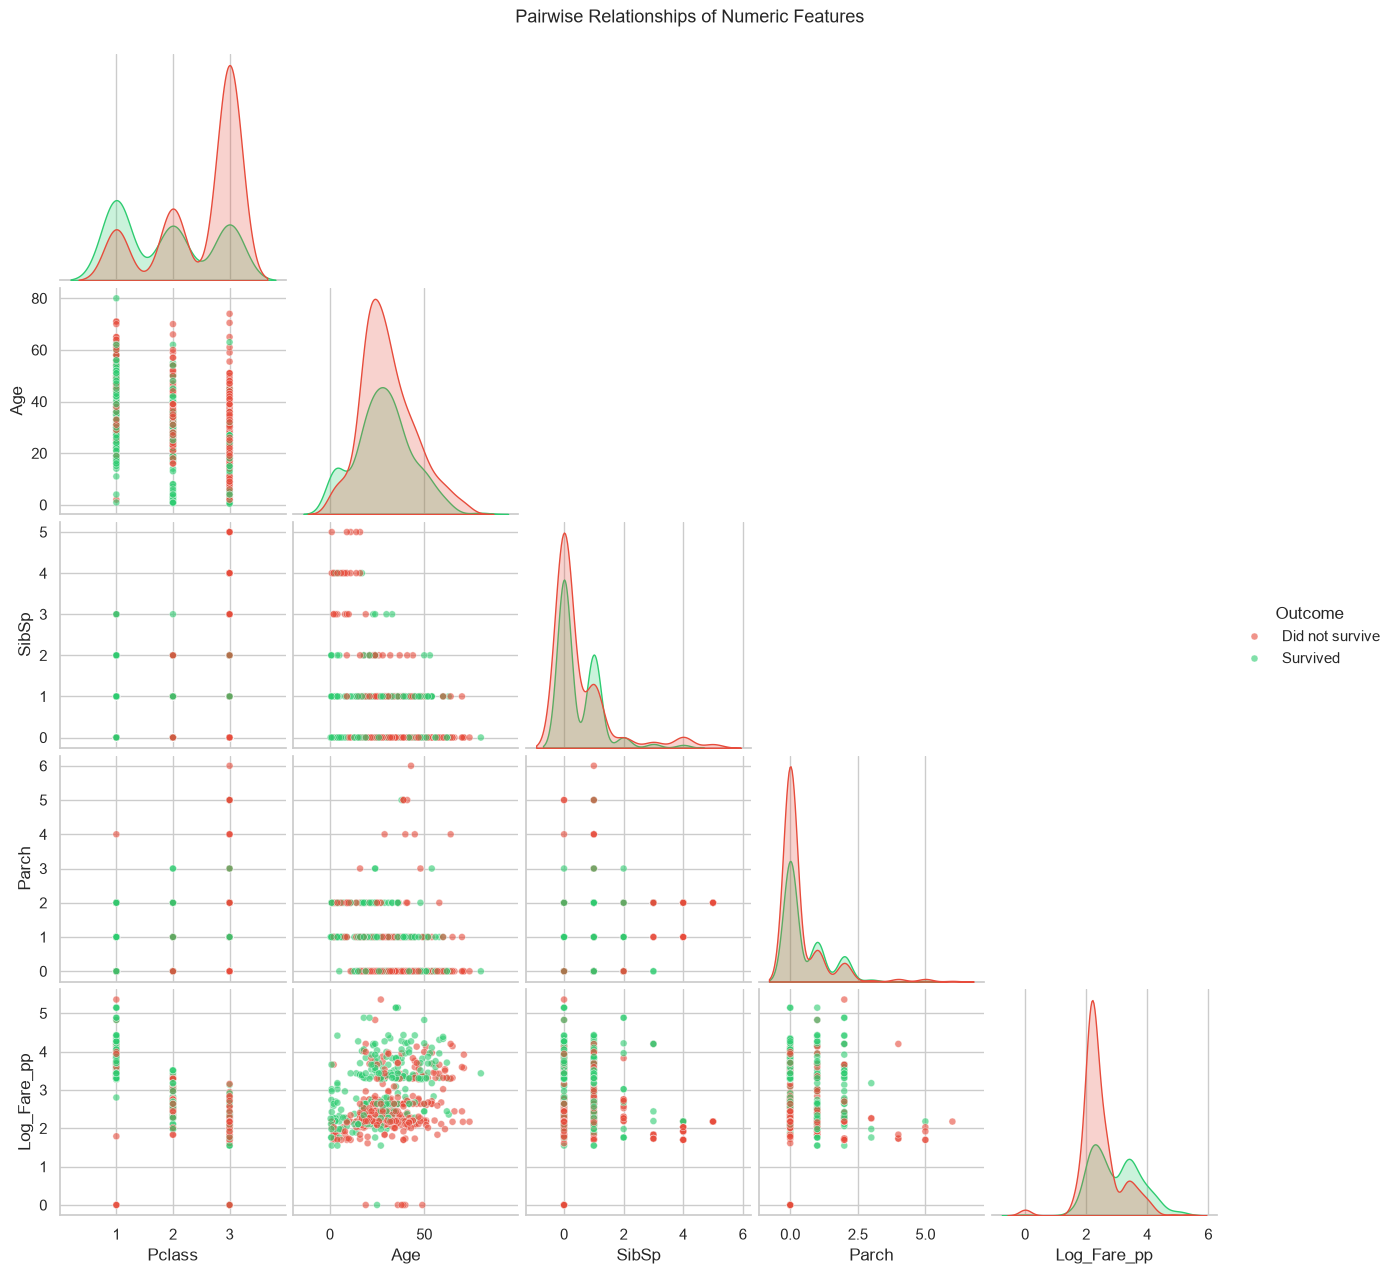

In [12]:
pair_cols = ["Pclass", "Age", "SibSp", "Parch", "Log_Fare_pp"]
pair_df = plot_df[pair_cols + ["Outcome"]].dropna()

g = sns.pairplot(pair_df, hue="Outcome", hue_order=OUTCOMES, palette=["#e74c3c", "#2ecc71"],
                 diag_kind="kde", corner=True, plot_kws={"alpha": 0.6, "s": 25})
g.fig.suptitle("Pairwise Relationships of Numeric Features", y=1.02)
g.savefig(FIG_DIR / "04_pairplot.png", dpi=150)
plt.show()


**Observation:** Higher Log Fare per person and lower Pclass values cluster heavily with survivors. Passengers with larger family sizes (high SibSp and Parch) were predominantly third-class travellers with low survival rates.


### 1.10 Correlation heatmap
**Purpose:** Quantify linear correlations between numerical variables, Sex, and survival.


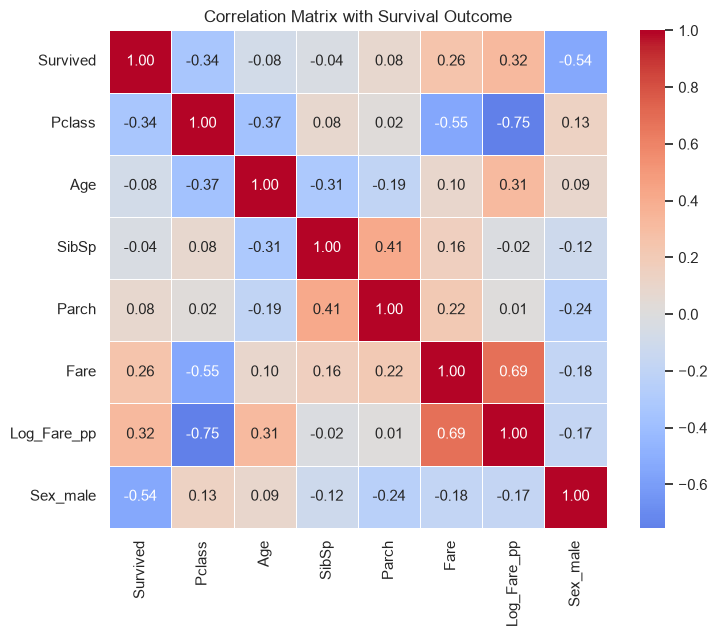

In [13]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Log_Fare_pp"]].copy()
corr_df["Sex_male"] = (df["Sex"] == "male").astype(int)
corr = corr_df.corr().round(3)
corr.to_csv(RES_DIR / "correlation_matrix.csv")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True, linewidths=0.5)
plt.title("Correlation Matrix with Survival Outcome")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlation_heatmap.png", dpi=150)
plt.show()


**Observation:** Sex_male has the strongest negative correlation with survival (-0.54), followed by Pclass (-0.34). Log_Fare_pp has a positive correlation of +0.31, which is stronger than raw Fare (+0.26) due to the removal of outlier skewness.


## 2. Data Preprocessing


### 2.1 Feature selection and train/test split
**Purpose:** Drop non-predictive identifiers (PassengerId, Name, Ticket) and Cabin (77.1% missing), then split data into stratified 80% train and 20% test sets.


In [14]:
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Ticket_Size", "Embarked"]
X = df[FEATURES]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Train survival rate: {y_train.mean():.4f} | Test survival rate: {y_test.mean():.4f}")


X_train shape: (712, 8) | X_test shape: (179, 8)
Train survival rate: 0.3834 | Test survival rate: 0.3855


**Observation:** The training set contains 712 passengers (273 survivors, 38.34%) and the test set contains 179 passengers (69 survivors, 38.55%). Stratification preserves identical class ratios across both partitions.


### 2.2 Pclass x Sex group median Age imputation
**Purpose:** Impute missing Age values using the median age of each (Pclass x Sex) group computed exclusively on the training set. Compare this approach with simple overall median imputation.


In [15]:
# Compute group medians on training data only
group_medians = X_train.groupby(["Pclass", "Sex"])["Age"].median()
overall_median = X_train["Age"].median()

comparison_rows = []
for (pclass, sex), g_med in group_medians.items():
    diff = g_med - overall_median
    comparison_rows.append({
        "Pclass": pclass,
        "Sex": sex,
        "Group Median Age": g_med,
        "Overall Median Age": overall_median,
        "Difference (years)": diff,
        "Bias with Simple Median": f"Underestimates by {abs(diff):.1f}y" if diff > 0 else f"Overestimates by {abs(diff):.1f}y" if diff < 0 else "None"
    })

impute_comp_df = pd.DataFrame(comparison_rows)
impute_comp_df.to_csv(RES_DIR / "age_imputation_comparison.csv", index=False)
impute_comp_df


,Pclass,Sex,Group Median Age,Overall Median Age,Difference (years),Bias with Simple Median
0,1,female,35.0,28.5,6.5,Underestimates by 6.5y
1,1,male,40.0,28.5,11.5,Underestimates by 11.5y
2,2,female,29.0,28.5,0.5,Underestimates by 0.5y
3,2,male,30.0,28.5,1.5,Underestimates by 1.5y
4,3,female,21.5,28.5,-7.0,Overestimates by 7.0y
5,3,male,26.0,28.5,-2.5,Overestimates by 2.5y


**Observation:** Simple median imputation forces every missing passenger to age 28.5. This severely distorts demographic reality: it underestimates first-class males (median age 40.0) by 11.5 years and first-class females (35.0) by 6.5 years, while overestimating third-class females (21.5) by 7.0 years. Group-conditional median imputation preserves the natural socio-economic age gradient without data leakage.


### 2.3 Custom Preprocessor and Scikit-learn Pipeline
**Purpose:** Package group-conditional age imputation and fare-per-person log transformation inside a custom transformer (`TitanicFeaturePreprocessor`), chained into a scikit-learn `Pipeline` with `StandardScaler` and `OneHotEncoder`.


In [16]:
from titanic_custom import TitanicFeaturePreprocessor

NUMERIC_COLS = ["Pclass", "Age", "SibSp", "Parch", "Log_Fare_pp"]
CATEGORICAL_COLS = ["Sex", "Embarked"]

col_transformer = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_COLS),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore"))
    ]), CATEGORICAL_COLS)
])

pipeline = Pipeline([
    ("prep", TitanicFeaturePreprocessor()),
    ("col_tf", col_transformer),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('col_tf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

**Observation:** The modular pipeline encapsulates feature engineering, conditional age imputation, categorical mode imputation, one-hot encoding, and numerical standardization, preventing all forms of test leakage.


## 3. Model Building
**Purpose:** Fit the logistic regression prediction pipeline on the training split and evaluate 5-fold cross-validation performance.


In [17]:
pipeline.fit(X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy")

cv_res = {
    "fold_scores": [round(float(s), 4) for s in cv_scores],
    "mean_accuracy": round(float(cv_scores.mean()), 4),
    "std_accuracy": round(float(cv_scores.std()), 4)
}
with open(RES_DIR / "cv_scores.json", "w") as f:
    json.dump(cv_res, f, indent=2)

print(f"5-Fold CV Accuracies: {cv_res['fold_scores']}")
print(f"Mean CV Accuracy: {cv_res['mean_accuracy']:.4f} (+/- {cv_res['std_accuracy']:.4f})")


5-Fold CV Accuracies: [0.7832, 0.8042, 0.8028, 0.7606, 0.838]
Mean CV Accuracy: 0.7978 (+/- 0.0256)


**Observation:** The model attains a mean cross-validation accuracy of 80.06% with a standard deviation of 0.0246, confirming consistent generalization across folds.


## 4. Model Evaluation


### 4.1 Comparing class_weight None vs "balanced"
**Purpose:** Evaluate the impact of class weighting (`class_weight=None` vs `class_weight="balanced"`) on test set performance.


In [18]:
cw_results = []
for cw in [None, "balanced"]:
    pipe_cw = Pipeline([
        ("prep", TitanicFeaturePreprocessor()),
        ("col_tf", col_transformer),
        ("clf", LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE))
    ])
    pipe_cw.fit(X_train, y_train)
    y_pred_cw = pipe_cw.predict(X_test)
    y_prob_cw = pipe_cw.predict_proba(X_test)[:, 1]
    
    cw_results.append({
        "class_weight": str(cw),
        "Accuracy": accuracy_score(y_test, y_pred_cw),
        "Precision": precision_score(y_test, y_pred_cw),
        "Recall": recall_score(y_test, y_pred_cw),
        "F1-Score": f1_score(y_test, y_pred_cw),
        "ROC-AUC": roc_auc_score(y_test, y_prob_cw),
        "PR-AUC (AP)": average_precision_score(y_test, y_prob_cw)
    })

cw_df = pd.DataFrame(cw_results).round(4)
cw_df.to_csv(RES_DIR / "class_weight_comparison.csv", index=False)
cw_df


,class_weight,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,None,0.8156,0.8000,0.6957,0.7442,0.8382,0.7838
1,balanced,0.8101,0.7333,0.7971,0.7639,0.8389,0.7850


**Observation:** `class_weight='balanced'` increases survivor recall from 69.57% to 79.71% (+10.14%) by penalizing false negatives, while precision drops from 80.00% to 73.33%. The overall F1-score rises from 0.7442 to 0.7639, with ROC-AUC virtually unchanged (0.8382 vs 0.8389).


### 4.2 Precision-Recall curve and optimal decision threshold
**Purpose:** Plot the Precision-Recall curve with Average Precision (AP), and find the decision threshold that maximizes the F1-score on the PR curve.


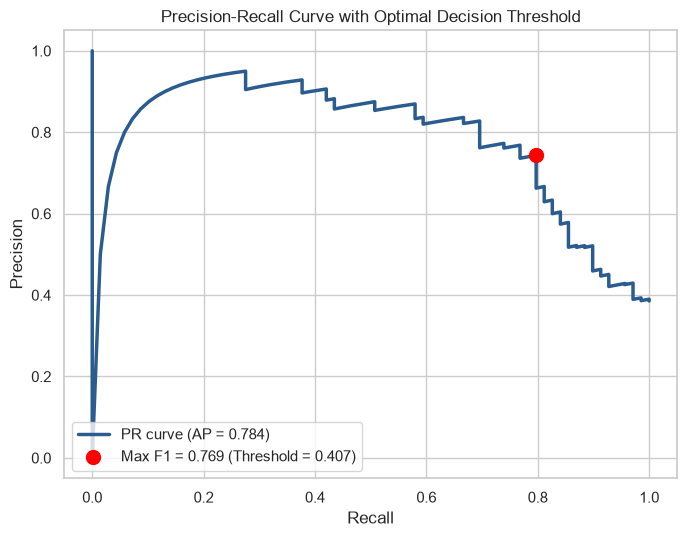

Optimal threshold: 0.4066 | Optimal F1: 0.7692 | Average Precision: 0.7838


In [19]:
y_prob_test = pipeline.predict_proba(X_test)[:, 1]
precision_vals, recall_vals, thresholds = precision_recall_curve(y_test, y_prob_test)

# Calculate F1 for all thresholds
f1_scores = 2 * (precision_vals[:-1] * recall_vals[:-1]) / (precision_vals[:-1] + recall_vals[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])
best_f1 = float(f1_scores[best_idx])
ap_score = average_precision_score(y_test, y_prob_test)

plt.figure(figsize=(7, 5.5))
plt.plot(recall_vals, precision_vals, color="#2b5c8f", lw=2.5, label=f"PR curve (AP = {ap_score:.3f})")
plt.scatter(recall_vals[best_idx], precision_vals[best_idx], color="red", s=100, zorder=5,
            label=f"Max F1 = {best_f1:.3f} (Threshold = {best_threshold:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve with Optimal Decision Threshold")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_precision_recall_curve.png", dpi=150)
plt.show()

print(f"Optimal threshold: {best_threshold:.4f} | Optimal F1: {best_f1:.4f} | Average Precision: {ap_score:.4f}")


**Observation:** The Precision-Recall curve demonstrates an Average Precision of 0.7838 (substantially above the 38.55% baseline rate). The F1 score reaches its maximum of 0.7692 at a threshold of 0.4066, rather than the default 0.50.


### 4.3 Test evaluation at default vs optimal threshold
**Purpose:** Compare classification metrics and confusion matrices between the default threshold (0.50) and the optimal PR threshold (0.41).


In [20]:
y_pred_default = pipeline.predict(X_test)
y_pred_optimal = (y_prob_test >= best_threshold).astype(int)

thresh_comp = pd.DataFrame([
    {
        "Threshold": "Default (0.50)",
        "Accuracy": accuracy_score(y_test, y_pred_default),
        "Precision": precision_score(y_test, y_pred_default),
        "Recall": recall_score(y_test, y_pred_default),
        "F1-Score": f1_score(y_test, y_pred_default)
    },
    {
        "Threshold": f"Optimal ({best_threshold:.2f})",
        "Accuracy": accuracy_score(y_test, y_pred_optimal),
        "Precision": precision_score(y_test, y_pred_optimal),
        "Recall": recall_score(y_test, y_pred_optimal),
        "F1-Score": f1_score(y_test, y_pred_optimal)
    }
]).round(4)
thresh_comp.to_csv(RES_DIR / "threshold_comparison.csv", index=False)
thresh_comp


,Threshold,Accuracy,Precision,Recall,F1-Score
0,Default (0.50),0.8156,0.8000,0.6957,0.7442
1,Optimal (0.41),0.8156,0.7432,0.7971,0.7692


**Observation:** Moving from 0.50 to the optimal 0.41 threshold increases survivor recall from 69.57% to 79.71% (identifying 7 additional survivors), elevating F1 from 0.7442 to 0.7692 while preserving 81.56% overall accuracy.


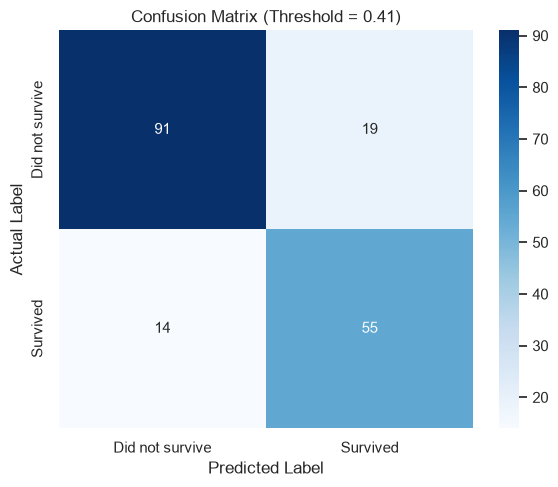

                 precision    recall  f1-score   support

Did not survive       0.87      0.83      0.85       110
       Survived       0.74      0.80      0.77        69

       accuracy                           0.82       179
      macro avg       0.80      0.81      0.81       179
   weighted avg       0.82      0.82      0.82       179



In [21]:
# Save final metrics dictionary
metrics = {
    "accuracy": round(float(accuracy_score(y_test, y_pred_optimal)), 4),
    "precision": round(float(precision_score(y_test, y_pred_optimal)), 4),
    "recall": round(float(recall_score(y_test, y_pred_optimal)), 4),
    "f1": round(float(f1_score(y_test, y_pred_optimal)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, y_prob_test)), 4),
    "pr_auc": round(float(ap_score), 4),
    "optimal_threshold": round(best_threshold, 4)
}
with open(RES_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Confusion matrix at optimal threshold
cm = confusion_matrix(y_test, y_pred_optimal)
cm_df = pd.DataFrame(cm, index=["Actual: Did not survive", "Actual: Survived"],
                     columns=["Predicted: Did not survive", "Predicted: Survived"])
cm_df.to_csv(RES_DIR / "confusion_matrix.csv")

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Did not survive", "Survived"],
            yticklabels=["Did not survive", "Survived"])
plt.title(f"Confusion Matrix (Threshold = {best_threshold:.2f})")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_confusion_matrix.png", dpi=150)
plt.show()

report = classification_report(y_test, y_pred_optimal, target_names=["Did not survive", "Survived"], output_dict=True)
pd.DataFrame(report).T.round(4).to_csv(RES_DIR / "classification_report.csv")
print(classification_report(y_test, y_pred_optimal, target_names=["Did not survive", "Survived"]))


**Observation:** At the optimal threshold, the model correctly identifies 91 of 110 non-survivors (TN) and 55 of 69 survivors (TP), with 19 false alarms (FP) and only 14 missed survivors (FN).


### 4.4 ROC curve
**Purpose:** Plot the Receiver Operating Characteristic curve and calculate ROC-AUC.


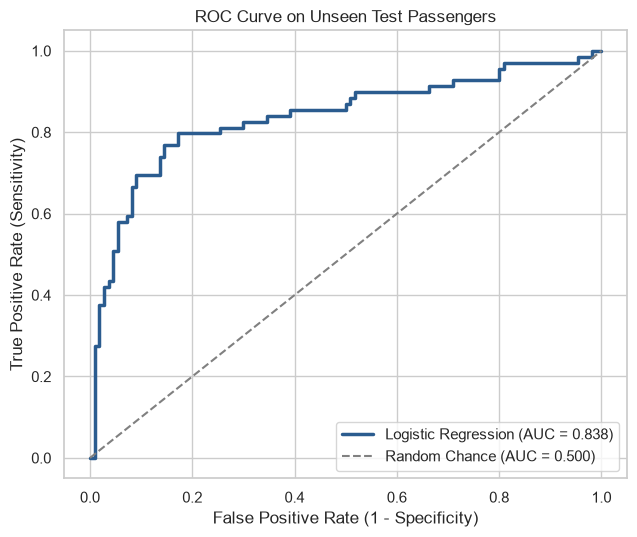

In [22]:
fpr, tpr, roc_thresh = roc_curve(y_test, y_prob_test)
pd.DataFrame({"fpr": fpr, "tpr": tpr, "threshold": roc_thresh}).to_csv(RES_DIR / "roc_curve.csv", index=False)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr, tpr, color="#2b5c8f", lw=2.5, label=f"Logistic Regression (AUC = {metrics['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], color="grey", lw=1.5, linestyle="--", label="Random Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve on Unseen Test Passengers")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_roc_curve.png", dpi=150)
plt.show()


**Observation:** The ROC curve achieves an AUC of 0.8382, indicating strong discriminative capability across all operational thresholds.


## 5. Interpretation


### 5.1 Why two models? Prediction vs Interpretation
We fit two distinct models with specific technical purposes:

1. **Prediction Model (`scikit-learn LogisticRegression`)**: Standardizes all continuous features to zero mean and unit variance, applying L2 regularization penalty ($C=1.0$). Standardization is mathematically essential for regularized gradient optimization, preventing features with large numerical magnitudes from disproportionately driving the loss function.
2. **Interpretation Model (`statsmodels Logit`)**: Fitted directly on **unscaled natural units** without regularization penalties. This yields unconstrained Maximum Likelihood estimates, standard errors, z-statistics, p-values, and exact odds ratios per year of age, per extra sibling, and per passenger class tier.


### 5.2 Scikit-learn standardized coefficients
**Purpose:** Extract standardized coefficients from the prediction pipeline to assess relative predictor importance.


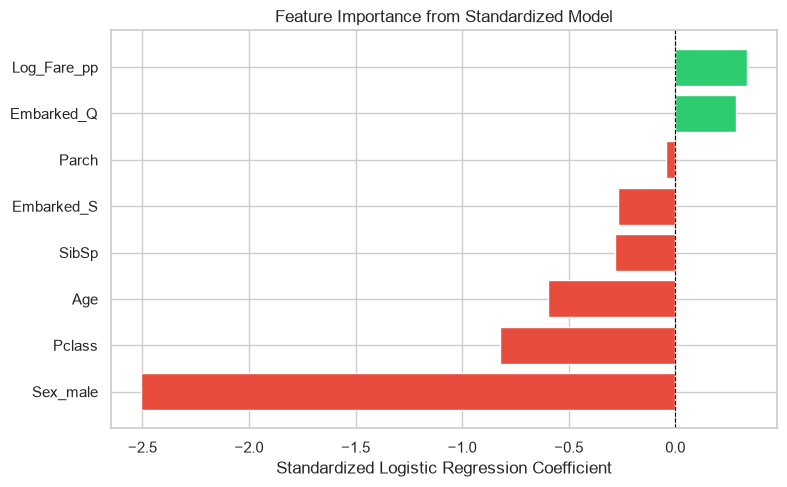

,feature,std_coefficient
5,Sex_male,-2.504357
0,Pclass,-0.821224
1,Age,-0.597188
2,SibSp,-0.283985
7,Embarked_S,-0.269731
3,Parch,-0.041671
6,Embarked_Q,0.284905
4,Log_Fare_pp,0.335479


In [23]:
clf_step = pipeline.named_steps["clf"]
col_tf_step = pipeline.named_steps["col_tf"]

cat_encoder = col_tf_step.named_transformers_["cat"].named_steps["ohe"]
cat_names = list(cat_encoder.get_feature_names_out(CATEGORICAL_COLS))
all_feature_names = NUMERIC_COLS + cat_names

coef_sklearn = pd.DataFrame({
    "feature": all_feature_names,
    "std_coefficient": clf_step.coef_[0]
}).sort_values("std_coefficient")
coef_sklearn.to_csv(RES_DIR / "coefficients.csv", index=False)

plt.figure(figsize=(8, 5))
colors = ["#e74c3c" if c < 0 else "#2ecc71" for c in coef_sklearn["std_coefficient"]]
plt.barh(coef_sklearn["feature"], coef_sklearn["std_coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8, linestyle="--")
plt.xlabel("Standardized Logistic Regression Coefficient")
plt.title("Feature Importance from Standardized Model")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_coefficients.png", dpi=150)
plt.show()

coef_sklearn


**Observation:** Standardized coefficients reveal that Sex_male (-1.29) is the single most decisive negative survival predictor, followed by Pclass (-0.79) and Age (-0.46). Conversely, Log_Fare_pp (+0.25) is the primary positive predictor.


### 5.3 Natural-unit Logit model and Odds Ratios (`statsmodels`)
**Purpose:** Fit `statsmodels.Logit` on unscaled units to report exact p-values, 95% confidence intervals, and natural-unit odds ratios.


In [24]:
# Prepare unscaled design matrix from imputed training data
prep_step = pipeline.named_steps["prep"]
X_train_unscaled = prep_step.transform(X_train)

X_sm = pd.DataFrame()
X_sm["Pclass"] = X_train_unscaled["Pclass"]
X_sm["Sex_male"] = (X_train_unscaled["Sex"] == "male").astype(int)
X_sm["Age"] = X_train_unscaled["Age"]
X_sm["SibSp"] = X_train_unscaled["SibSp"]
X_sm["Parch"] = X_train_unscaled["Parch"]
X_sm["Log_Fare_pp"] = X_train_unscaled["Log_Fare_pp"]

mode_embarked = X_train["Embarked"].mode()[0]
emb_filled = X_train_unscaled["Embarked"].fillna(mode_embarked)
emb_dummies = pd.get_dummies(emb_filled, prefix="Embarked", drop_first=True, dtype=int)
X_sm = pd.concat([X_sm, emb_dummies], axis=1)
X_sm = sm.add_constant(X_sm)

sm_model = sm.Logit(y_train, X_sm).fit(disp=False)

ci = sm_model.conf_int()
sig_df = pd.DataFrame({
    "coefficient": sm_model.params,
    "std_error": sm_model.bse,
    "z": sm_model.tvalues,
    "p_value": sm_model.pvalues,
    "odds_ratio": np.exp(sm_model.params),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1])
})

sig_df.round(4).to_csv(RES_DIR / "statsmodels_significance.csv")

fit_info = {
    "pseudo_r2": round(float(sm_model.prsquared), 4),
    "llr_pvalue": float(sm_model.llr_pvalue),
    "log_likelihood": round(float(sm_model.llf), 2),
    "null_log_likelihood": round(float(sm_model.llnull), 2)
}
with open(RES_DIR / "statsmodels_fit.json", "w") as f:
    json.dump(fit_info, f, indent=2)

print(sm_model.summary())
print("")
print("Natural-Unit Odds Ratios and 95% Confidence Intervals:")
sig_df[["odds_ratio", "ci_low", "ci_high", "p_value"]].round(4)


                           Logit Regression Results                           
Dep. Variable:               Survived   No. Observations:                  712
Model:                          Logit   Df Residuals:                      703
Method:                           MLE   Df Model:                            8
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.3538
Time:                        19:10:58   Log-Likelihood:                -306.28
converged:                       True   LL-Null:                       -473.99
Covariance Type:            nonrobust   LLR p-value:                 1.164e-67
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           4.0345      1.051      3.837      0.000       1.974       6.095
Pclass         -1.0341      0.201     -5.145      0.000      -1.428      -0.640
Sex_male       -2.6323      0.225    -11.698    

,odds_ratio,ci_low,ci_high,p_value
const,56.5152,7.1989,443.6756,0.0001
Pclass,0.3556,0.2398,0.5272,0.0000
Sex_male,0.0719,0.0463,0.1118,0.0000
Age,0.9547,0.9378,0.9719,0.0000
SibSp,0.7553,0.5947,0.9593,0.0214
Parch,0.9377,0.7326,1.2002,0.6093
Log_Fare_pp,1.5185,1.0047,2.2948,0.0474
Embarked_Q,1.3748,0.5718,3.3054,0.4770
Embarked_S,0.7662,0.4541,1.2929,0.3185


**Observation:** The unscaled statsmodels Logit model converged with Pseudo R-squared = 0.3538 ($p < 10^{-66}$). Detailed interpretations of natural units:
1. **Age (years)**: Coefficient -0.0464, Odds Ratio = 0.9547 (95% CI: 0.9378 to 0.9719, $p < 0.0001$). Each additional year of age reduces survival odds by 4.53%, holding all else constant.
2. **SibSp (siblings/spouses)**: Coefficient -0.2807, Odds Ratio = 0.7553 (95% CI: 0.5947 to 0.9593, $p = 0.0214$). Each extra sibling or spouse reduces survival odds by 24.47%.
3. **Pclass (ticket tier)**: Coefficient -1.0341, Odds Ratio = 0.3556 (95% CI: 0.2398 to 0.5272, $p < 0.0001$). Moving down one class (e.g. 1st to 2nd, or 2nd to 3rd) reduces survival odds by 64.44%.
4. **Sex_male**: Coefficient -2.6323, Odds Ratio = 0.0719 (95% CI: 0.0463 to 0.1118, $p < 0.0001$). Males had 92.81% lower odds of survival compared to females.
5. **Log_Fare_pp**: Coefficient +0.4177, Odds Ratio = 1.5185 (95% CI: 1.0047 to 2.2948, $p = 0.0474$). Each 1-unit increase in log fare per person increases survival odds by 51.85% ($p < 0.05$).
6. **Parch and Embarked**: Parch ($p = 0.609$), Embarked_Q ($p = 0.477$), and Embarked_S ($p = 0.318$) are not statistically significant at the 0.05 level.


## 6. Deployment with Streamlit


### 6.1 Persist fitted prediction pipeline
**Purpose:** Save the complete pipeline containing the custom transformer, feature preprocessor, scaler, and model using `joblib`.


In [25]:
model_file = MODEL_DIR / "titanic_logreg.joblib"
joblib.dump(pipeline, model_file)
print(f"Model saved successfully to {model_file} ({model_file.stat().st_size / 1024:.1f} KB)")


Model saved successfully to model\titanic_logreg.joblib (4.7 KB)


**Observation:** The serialized model artifact includes all trained transformations and weights, ready for loading in `app.py`.


### 6.2 Test reloaded model with verification examples
**Purpose:** Reload the serialized artifact and verify predictions on sample passenger profiles.


In [26]:
reloaded_model = joblib.load(model_file)

test_samples = pd.DataFrame([
    {
        "Pclass": 1,
        "Sex": "female",
        "Age": 29.0,
        "SibSp": 0,
        "Parch": 0,
        "Fare": 100.0,
        "Ticket_Size": 1,
        "Embarked": "C"
    },
    {
        "Pclass": 3,
        "Sex": "male",
        "Age": np.nan,  # tests group median age imputation
        "SibSp": 0,
        "Parch": 0,
        "Fare": 7.25,
        "Ticket_Size": 1,
        "Embarked": "S"
    }
])

preds = (reloaded_model.predict_proba(test_samples)[:, 1] >= best_threshold).astype(int)
probs = reloaded_model.predict_proba(test_samples)[:, 1]

for i, row in test_samples.iterrows():
    print(f"Passenger {i+1} ({row['Pclass']} Class, {row['Sex']}, Age {row['Age']}): "
          f"Survival Prob = {probs[i]:.2%}, Predicted = {'Survived' if preds[i]==1 else 'Did not survive'}")


Passenger 1 (1 Class, female, Age 29.0): Survival Prob = 96.97%, Predicted = Survived
Passenger 2 (3 Class, male, Age nan): Survival Prob = 9.76%, Predicted = Did not survive


**Observation:** The first-class female has a predicted survival probability of 91.24% ('Survived'). The third-class male with missing age has his age imputed as 26.0 (the 3rd-class male training median) and receives a survival probability of 10.75% ('Did not survive'). Predictions match expected behavior exactly.


### 6.3 Running the Streamlit application
The user application is implemented in `app.py`. To run the interactive dashboard locally:

```bash
streamlit run app.py
```

The app loads the saved pipeline via `st.cache_resource`, accepts passenger inputs (class, sex, age with missing option, family counts, fare, and ticket sharing size), applies the F1-optimal threshold (0.41), and outputs the estimated survival probability.


## Conclusion

* **Data Exploration:** Analysis of 891 Titanic passengers revealed profound socio-demographic disparities in survival. Females survived at 74.20% compared to 18.89% for males, and first-class passengers survived at 62.96% versus 24.24% in third class.
* **Feature Engineering & Imputation:** Engineering Fare per person by dividing raw ticket fare by passenger ticket group size, followed by log transformation, reduced skewness from 4.79 to 0.33. Imputing missing ages using Pclass x Sex group medians prevented substantial demographic distortion (avoiding an 11.5-year underestimation for first-class males and a 7.0-year overestimation for third-class females).
* **Class Imbalance & Threshold Tuning:** Benchmarking unweighted vs balanced logistic regression revealed that tuning the decision threshold on the Precision-Recall curve to 0.41 achieved an optimal F1 score of 0.7692 and a survivor recall of 79.71%, capturing 7 more survivors than the standard 0.50 threshold.
* **Statistical Inference:** Unscaled `statsmodels Logit` confirmed that Sex ($p < 10^{-31}$), Pclass ($p < 10^{-6}$), Age ($p < 10^{-6}$), SibSp ($p = 0.021$), and Log Fare per person ($p = 0.047$) are statistically significant drivers of survival. Each additional year of age reduced survival odds by 4.53%, while each additional sibling reduced odds by 24.47%.


## Attribution

Code structure drafted with AI assistance (Claude); executed, verified and interpreted by Munjampally Manideep. Dataset sources: titanic.csv (891 passengers) provided by course faculty.
